In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
 

### loading data

In [2]:

data_path = 'C:\\Users\\zakaria\\Documents\\ML\\laptop_price_predictor_project\\backend\\data\\raw\\laptop_scrap_data.csv'
df = pd.read_csv(data_path)


df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Gpu,OpSys,TouchScreen,Ips,X_res,...,ppi,Dedicated_Gpu,Ram_GB,Weight_kg,SSD,HHD,Storage_Type,Total_Storage_GB,Storage_Category,Price
0,MSI,MSI Prestige 16 AI+,16.0,2880 x 1800,Intel Core Ultra X7 358H,Intel Arc B390,Windows,0.0,0.0,2880.0,...,212.26,1.0,64.0,1.59,1000.0,0.0,SSD Only,1000.0,Standard (512GB-1TB),2728.8
1,MSI,MSI Prestige 16 AI+,16.0,2880 x 1800,Intel Core Ultra 9 386H,Intel Graphics (4-Cores),Windows,0.0,0.0,2880.0,...,212.26,0.0,64.0,1.59,1000.0,0.0,SSD Only,1000.0,Standard (512GB-1TB),2528.8
2,ASUS,ASUS Vivobook S16,16.0,1920 x 1200,AMD Ryzen AI 5 330,AMD Radeon 820M,Windows,0.0,0.0,1920.0,...,141.51,1.0,24.0,1.70,4000.0,0.0,SSD Only,4000.0,Very High (> 2TB),2428.8
3,Toshiba,Dynabook X series,13.3,1920 x 1200,Intel Core i5-1350P,Intel Iris Xe Graphics G7 (80EU),Windows,1.0,1.0,1920.0,...,170.24,0.0,16.0,0.93,512.0,0.0,SSD Only,512.0,Standard (512GB-1TB),1390.2
4,Lenovo,"Lenovo Legion 5a (15"", Gen 11, 15AGP11)",15.3,2560 x 1600,AMD Ryzen AI 9 465,NVIDIA GeForce RTX 5060 (Laptop),Windows,0.0,0.0,2560.0,...,197.31,1.0,32.0,1.87,1000.0,0.0,SSD Only,1000.0,Standard (512GB-1TB),2067.8


### statitical anaylsis

In [3]:
def columns_desc(df):
    print("the nombre oF Columns in the DataFrame:")
    print(len(list(df.columns)))
    print("\nColumns names:")
    print(list(df.columns))

columns_desc(df)

the nombre oF Columns in the DataFrame:
21

Columns names:
['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Gpu', 'OpSys', 'TouchScreen', 'Ips', 'X_res', 'Y_res', 'ppi', 'Dedicated_Gpu', 'Ram_GB', 'Weight_kg', 'SSD', 'HHD', 'Storage_Type', 'Total_Storage_GB', 'Storage_Category', 'Price']


In [4]:
def data_audit(df):
    #understanding data
    print(f"--- Dataset Overview ---")
    print(f"Shape: {df.shape}")
    print(f"Memory Usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    print(f"Duplicate Rows: {df.duplicated().sum()}")
    
    # Null Audit
    null_df = pd.DataFrame({
        'Null Count': df.isnull().sum(),
        'Null %': (df.isnull().sum() / len(df)) * 100,
        'Dtype': df.dtypes
    }).sort_values('Null %', ascending=False)
    print("\n--- Missing Value  ---")
    print(null_df.head(22))

data_audit(df)


--- Dataset Overview ---
Shape: (1563, 21)
Memory Usage: 0.43 MB
Duplicate Rows: 2

--- Missing Value  ---
                  Null Count    Null %    Dtype
Company                    3  0.191939      str
TypeName                   3  0.191939      str
Inches                     3  0.191939  float64
ScreenResolution           3  0.191939      str
Cpu                        3  0.191939      str
Gpu                        3  0.191939      str
OpSys                      3  0.191939      str
TouchScreen                3  0.191939  float64
Ips                        3  0.191939  float64
X_res                      3  0.191939  float64
Y_res                      3  0.191939  float64
ppi                        3  0.191939  float64
Dedicated_Gpu              3  0.191939  float64
Ram_GB                     3  0.191939  float64
Weight_kg                  3  0.191939  float64
SSD                        3  0.191939  float64
HHD                        3  0.191939  float64
Storage_Type               3 

-keep in mind to manage dulicated while cleaning
-delete nulls while clesaning

In [5]:

"""
print("\nDescriptive statistics (numeric):")
print(df[numeric_cols].describe())
"""

'\nprint("\nDescriptive statistics (numeric):")\nprint(df[numeric_cols].describe())\n'

In [6]:
def get_cols(df):
        numeric_cols = ['Inches', 'X_res', 'Y_res', 'ppi', 'Ram_GB', 'Weight_kg',
                'Total_Storage_GB', 'Price']

        categorical_cols = ['Company', 'TypeName', 'OpSys', 'TouchScreen', 'Ips',
                    'Dedicated_Gpu', 'Storage_Type', 'Storage_Category']
        
        #assert len(numeric_cols)+len(categorical_cols)==len(df.columns.tolist()),  "Column mismatch"

        return numeric_cols, categorical_cols


def manage_columns(df):
        storage_cols = ['Storage_Type', 'Total_Storage_GB']
        wehight_col = 'Weight_kg'
        performance_cols = ["Cpu","Gpu","Dedicated_Gpu", 'Ram_GB']
        screening_cols = ['Inches', 'X_res', 'Y_res', 'ppi', 'TouchScreen', 'Ips']
        general_cols = ['Company', 'TypeName', 'OpSys']
        target_col = 'Price'
        return storage_cols, wehight_col, performance_cols, screening_cols, general_cols, target_col




In [7]:
def categorical_frequency(df):
    nemeric_cols, categorical_cols = get_cols(df)
    print("\nFrequency of categorical features:")
    for col in categorical_cols:
        if col in df.columns:
            print(f"\n{col}:\n{df[col].value_counts().head(10)}")

categorical_frequency(df)




Frequency of categorical features:

Company:
Company
HP           468
Lenovo       411
ASUS         221
Dell         154
Acer         112
MSI           82
Gigabyte      24
Apple         22
Microsoft     20
Samsung       18
Name: count, dtype: int64

TypeName:
TypeName
HP 15                 106
Lenovo IdeaPad 1       47
HP OMEN 16             39
ASUS Vivobook 14       34
HP 17                  34
HP 14                  31
Lenovo LOQ 15          28
HP Victus 15           26
Dell 15                22
HP OmniBook X Flip     17
Name: count, dtype: int64

OpSys:
OpSys
Windows      1512
Chrome OS      26
macOS          22
Name: count, dtype: int64

TouchScreen:
TouchScreen
1.0    1133
0.0     427
Name: count, dtype: int64

Ips:
Ips
1.0    1116
0.0     444
Name: count, dtype: int64

Dedicated_Gpu:
Dedicated_Gpu
1.0    943
0.0    617
Name: count, dtype: int64

Storage_Type:
Storage_Type
SSD Only           1491
HDD Only             68
No Storage Data       1
Name: count, dtype: int64

Storage_C

In [8]:
numeric_cols, categorical_cols = get_cols(df)
categorical_cols

['Company',
 'TypeName',
 'OpSys',
 'TouchScreen',
 'Ips',
 'Dedicated_Gpu',
 'Storage_Type',
 'Storage_Category']

In [9]:
#the problem was in index so you delete index 0 so the followin item will take the place if you want to delete than delete index 0
categorical_hight_cols = []
campany= categorical_cols.pop(0)
type_name = categorical_cols.pop(0)
categorical_hight_cols.append(campany)
categorical_hight_cols.append(type_name)

categorical_cols

['OpSys',
 'TouchScreen',
 'Ips',
 'Dedicated_Gpu',
 'Storage_Type',
 'Storage_Category']

### EDA

UNIVARITE ANLYSIS

In [10]:

numeric_cols, categorical_cols = get_cols(df)

def distribution_plot_numeric(df,numeric_cols):
    fig, axes = plt.subplots(len(numeric_cols),2 , figsize=(20 ,6*len(numeric_cols)))
  
    for col in numeric_cols:   
        sns.histplot(df[col], kde=True,ax=axes[numeric_cols.index(col), 0],color="#f2110a")
        sns.boxplot(x=df[col], ax=axes[numeric_cols.index(col), 1])
        axes[numeric_cols.index(col), 0].set_title(f'Distribution of {col}')
        axes[numeric_cols.index(col), 0].set_xlabel(col)
        axes[numeric_cols.index(col), 0].set_ylabel('Frequency')
        
        axes[numeric_cols.index(col), 1].set_title(f'Box Plot of {col}')
        axes[numeric_cols.index(col), 1].set_xlabel(col)
        
    plt.tight_layout()
    plt.show()
    

def distribution_plot_categorical(df,categorical_cols):
    
    categorical_hight_cols = []
    campany= categorical_cols.pop(0)
    type_name = categorical_cols.pop(0)
    categorical_hight_cols.append(campany)
    categorical_hight_cols.append(type_name)
    
    
    sns.set_style('whitegrid')
    for col in categorical_cols:
        plt.figure(figsize=(10, 6))   
        counts = df[col].value_counts()       
        colors = sns.color_palette('pastel', len(counts))

        #plt.figure(figsize=(6,6))
        plt.pie(counts, labels=counts.index, autopct='%1.1f%%',
            colors=colors, startangle=140)
        plt.title(f'{col} distribution')
        plt.axis('equal')
    plt.show()
    for col in categorical_hight_cols:
        plt.figure(figsize=(10, 6))
        sns.set_style('whitegrid')
        counts = df[col].value_counts()        
        sns.countplot(x=col, data=df, palette='pastel')
    
        plt.title(f'{col} distribution')
        plt.axis('equal')
    plt.show()






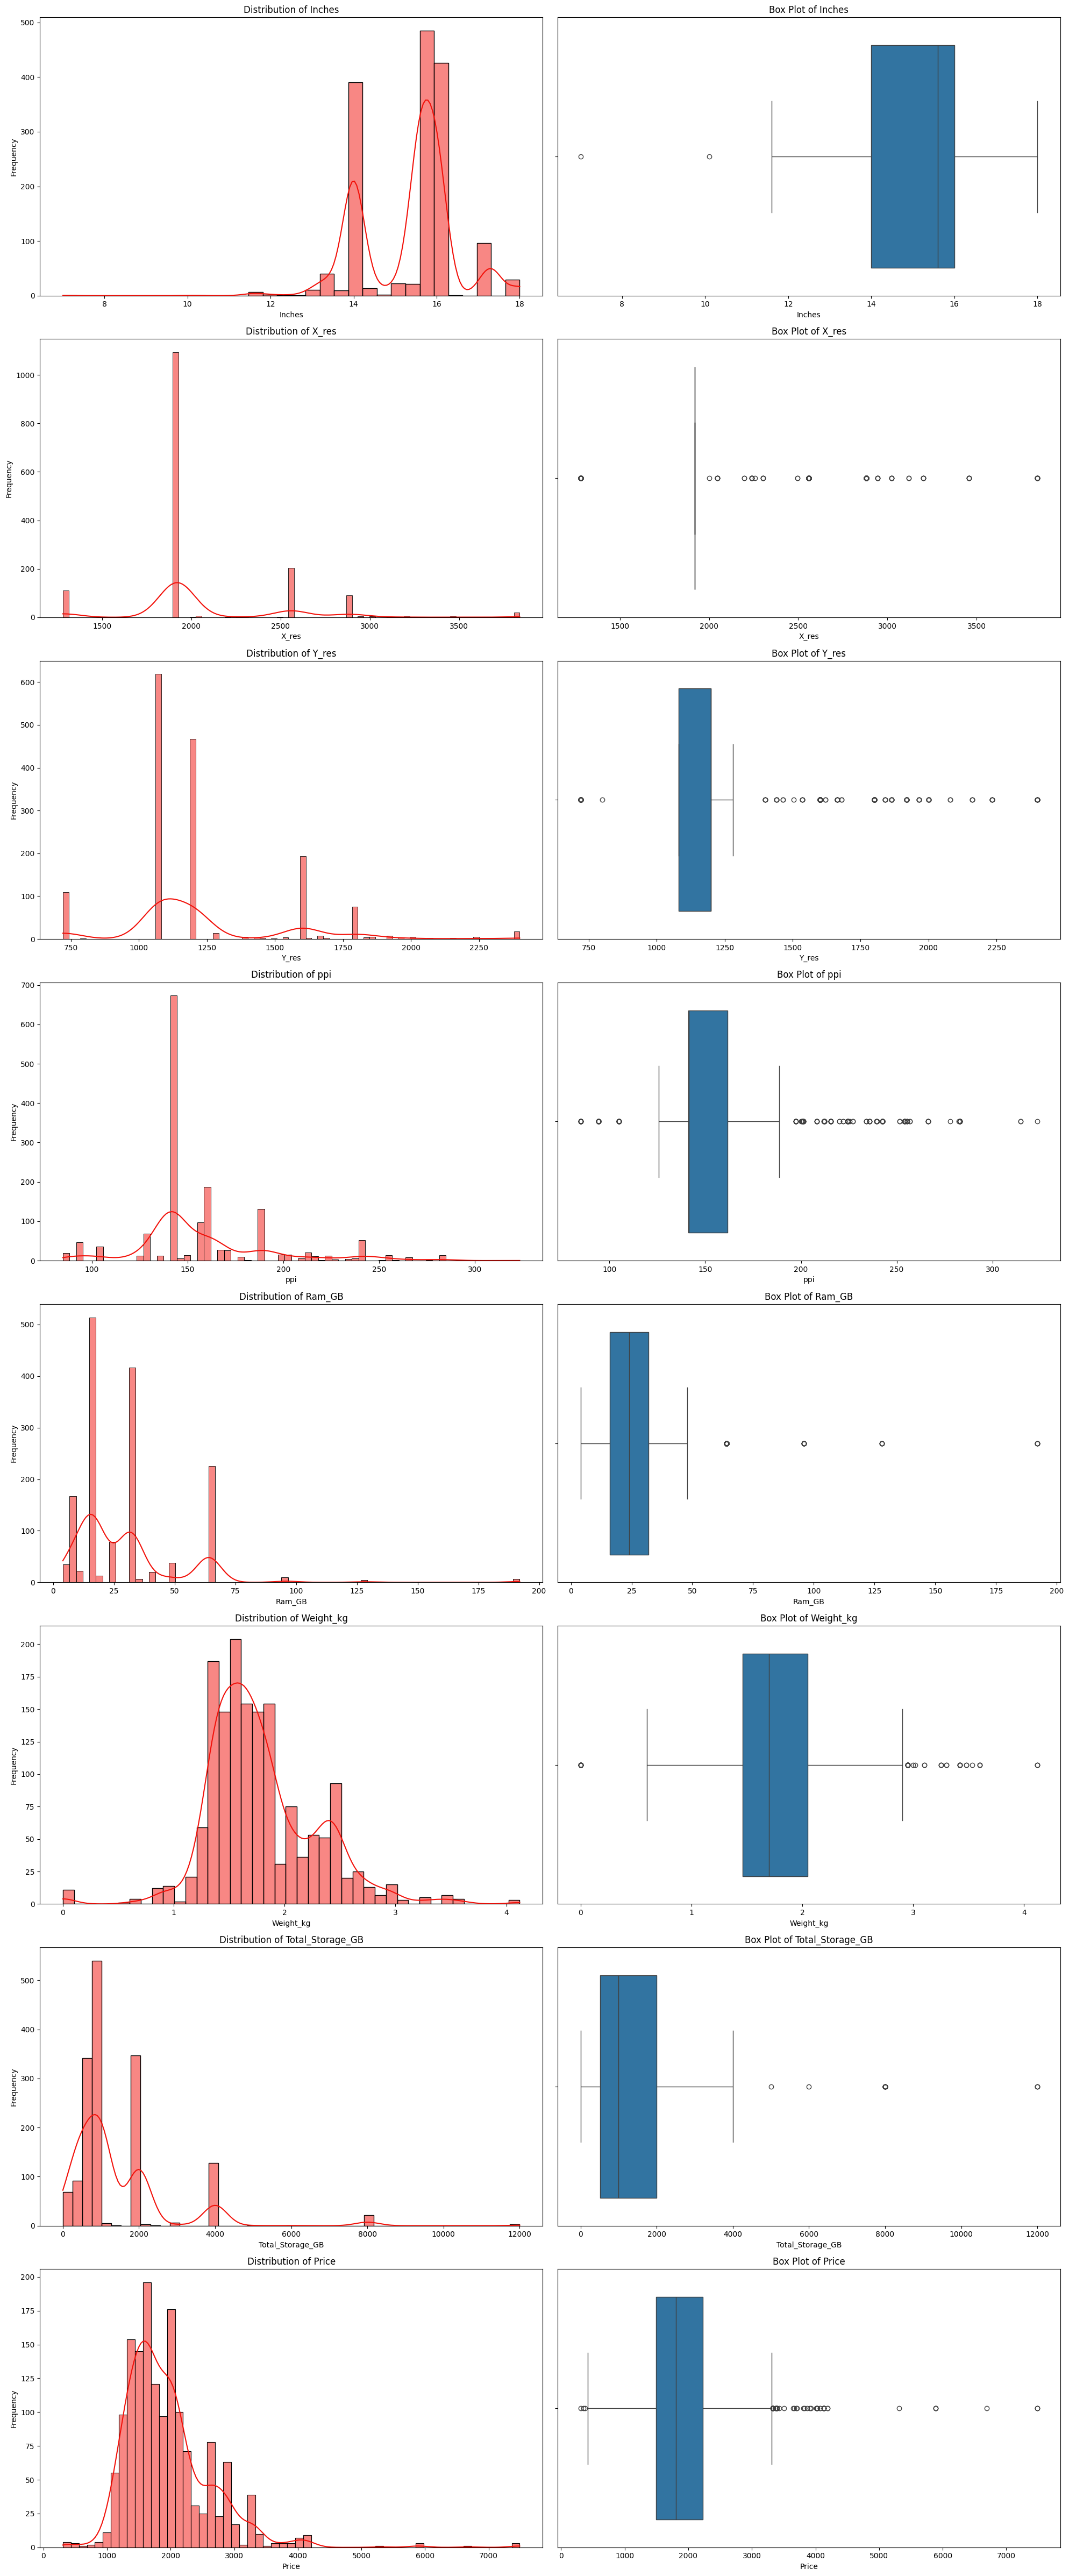

In [11]:
numeric_cols, categorical_cols = get_cols(df)
distribution_plot_numeric(df, numeric_cols)

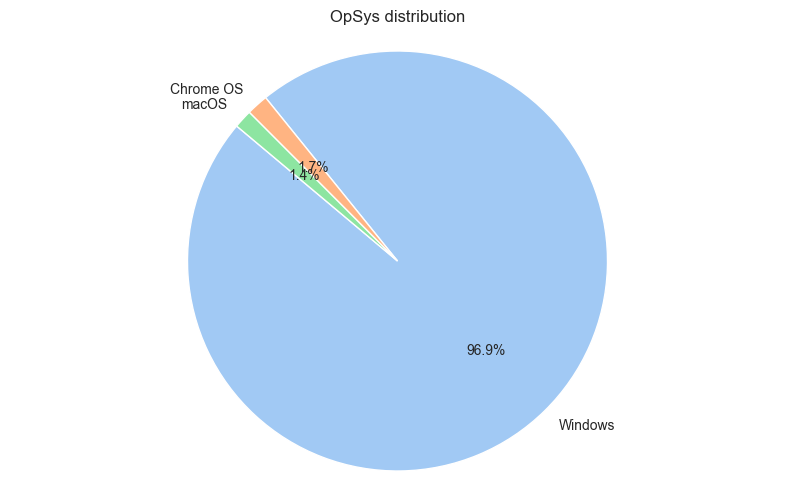

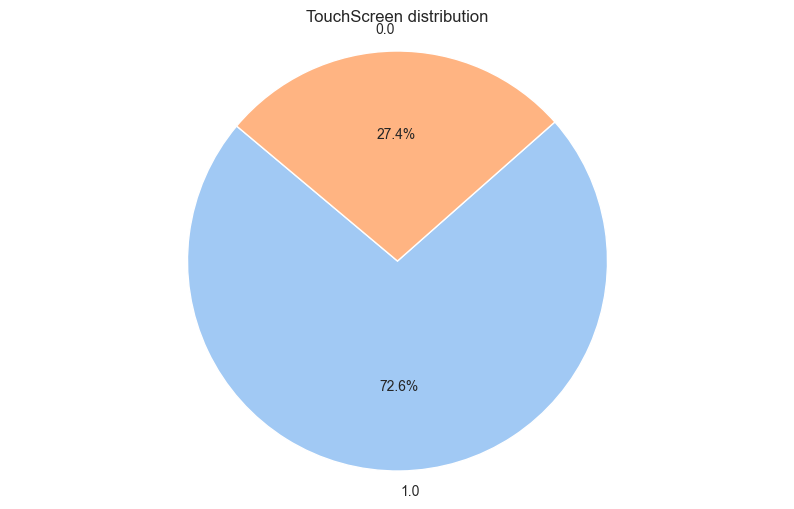

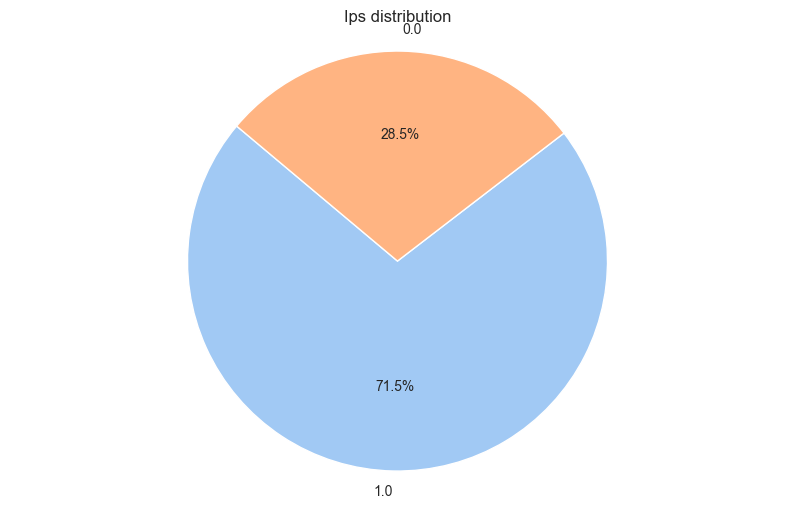

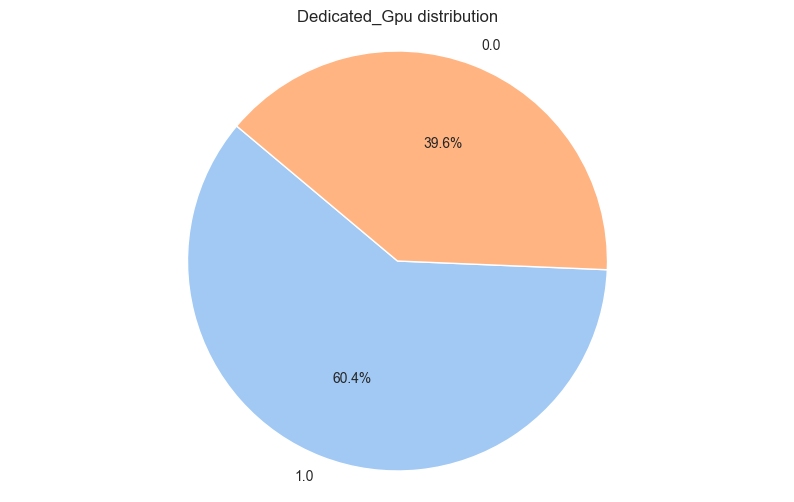

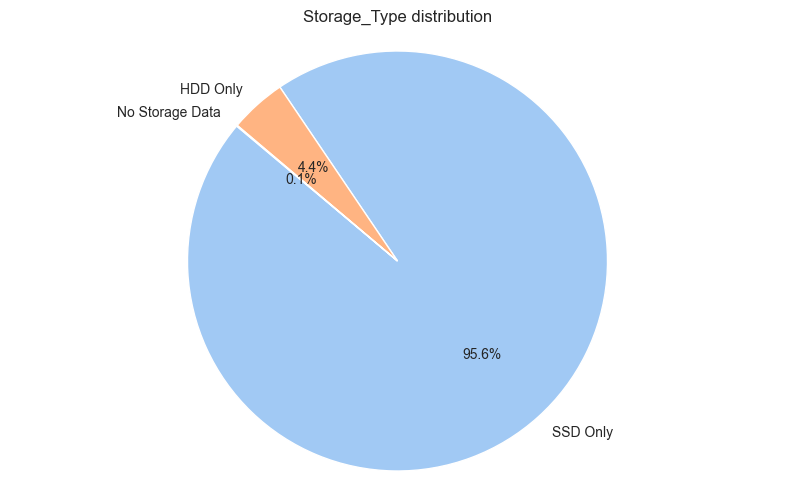

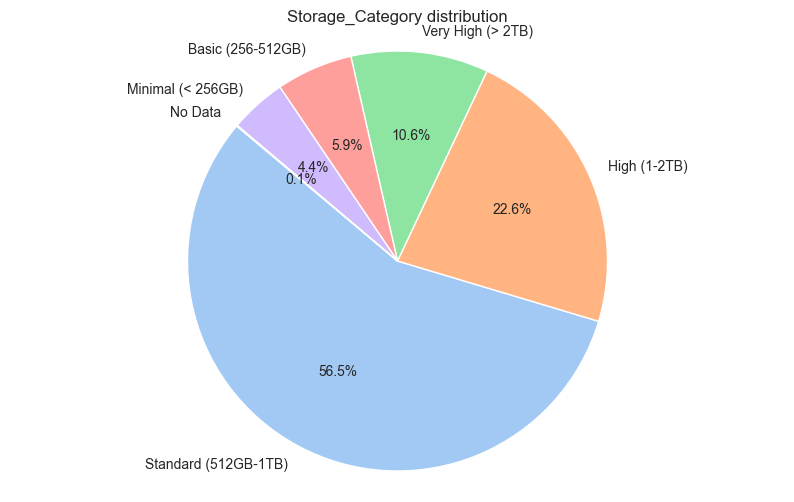

C:\Users\zakaria\AppData\Local\Temp\ipykernel_15744\1980546314.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='pastel')
C:\Users\zakaria\AppData\Local\Temp\ipykernel_15744\1980546314.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='pastel')


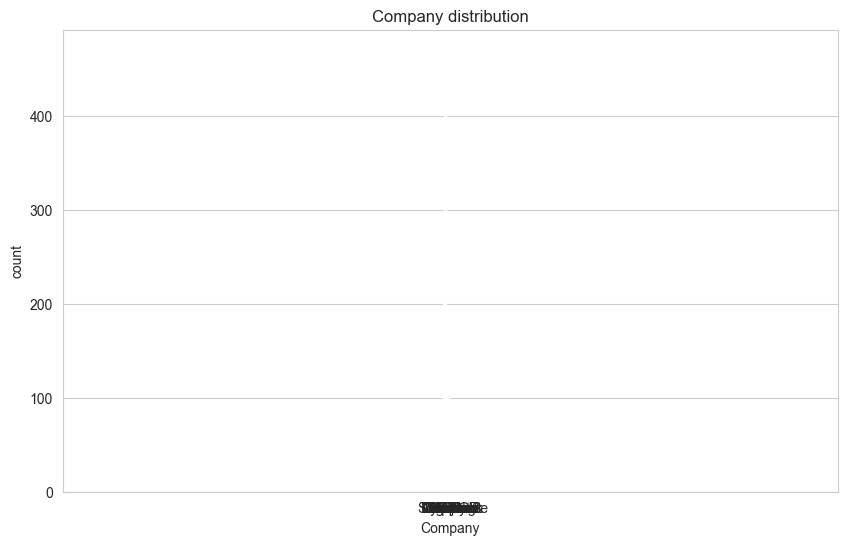

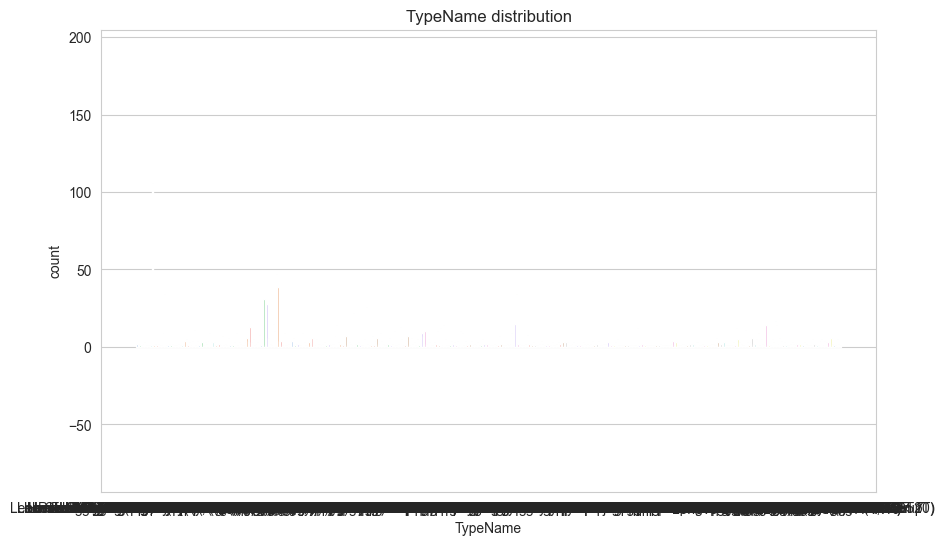

In [12]:
distribution_plot_categorical(df,categorical_cols)

BIVARITE ANYSIS


In [13]:
storage_cols, wehight_col, performance_cols, screening_cols, general_cols, target_col = manage_columns(df)

the affectation of the storage on our laptop prices

Text(0.5, 0.98, 'Pairplot of Storage Features vs Price')

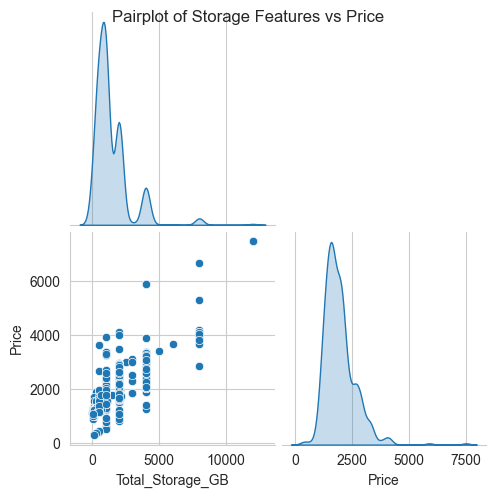

In [14]:
sns.pairplot(df[storage_cols + [target_col]], diag_kind='kde', corner=True)
plt.suptitle('Pairplot of Storage Features vs Price')

Text(0.5, 1.02, 'Pairplot of Performance Features vs Price')

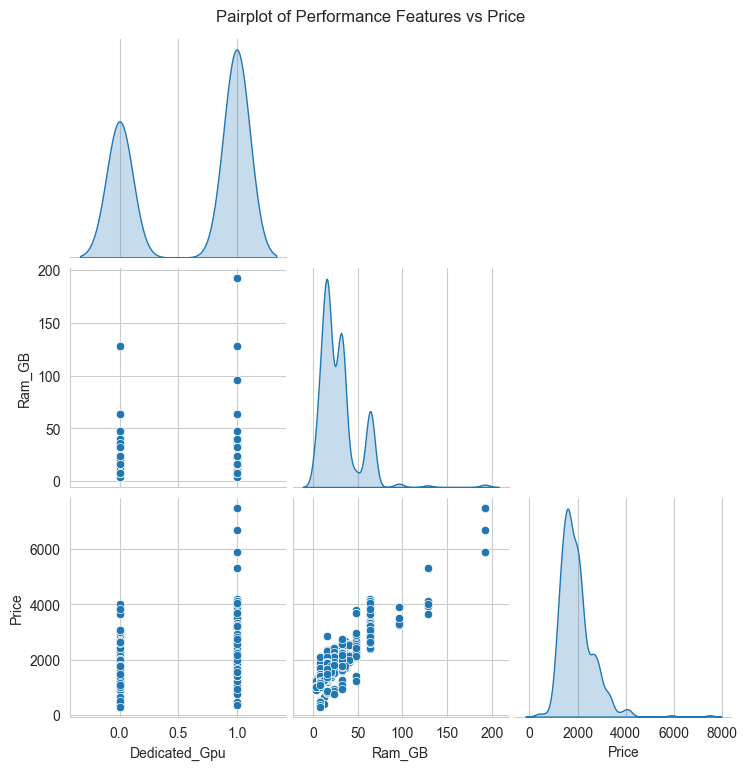

In [15]:
sns.pairplot(df[performance_cols + [target_col]], diag_kind='kde', corner=True)
plt.suptitle('Pairplot of Performance Features vs Price', y=1.02)

Text(0.5, 1.02, 'Pairplot of Screening Features vs Price')

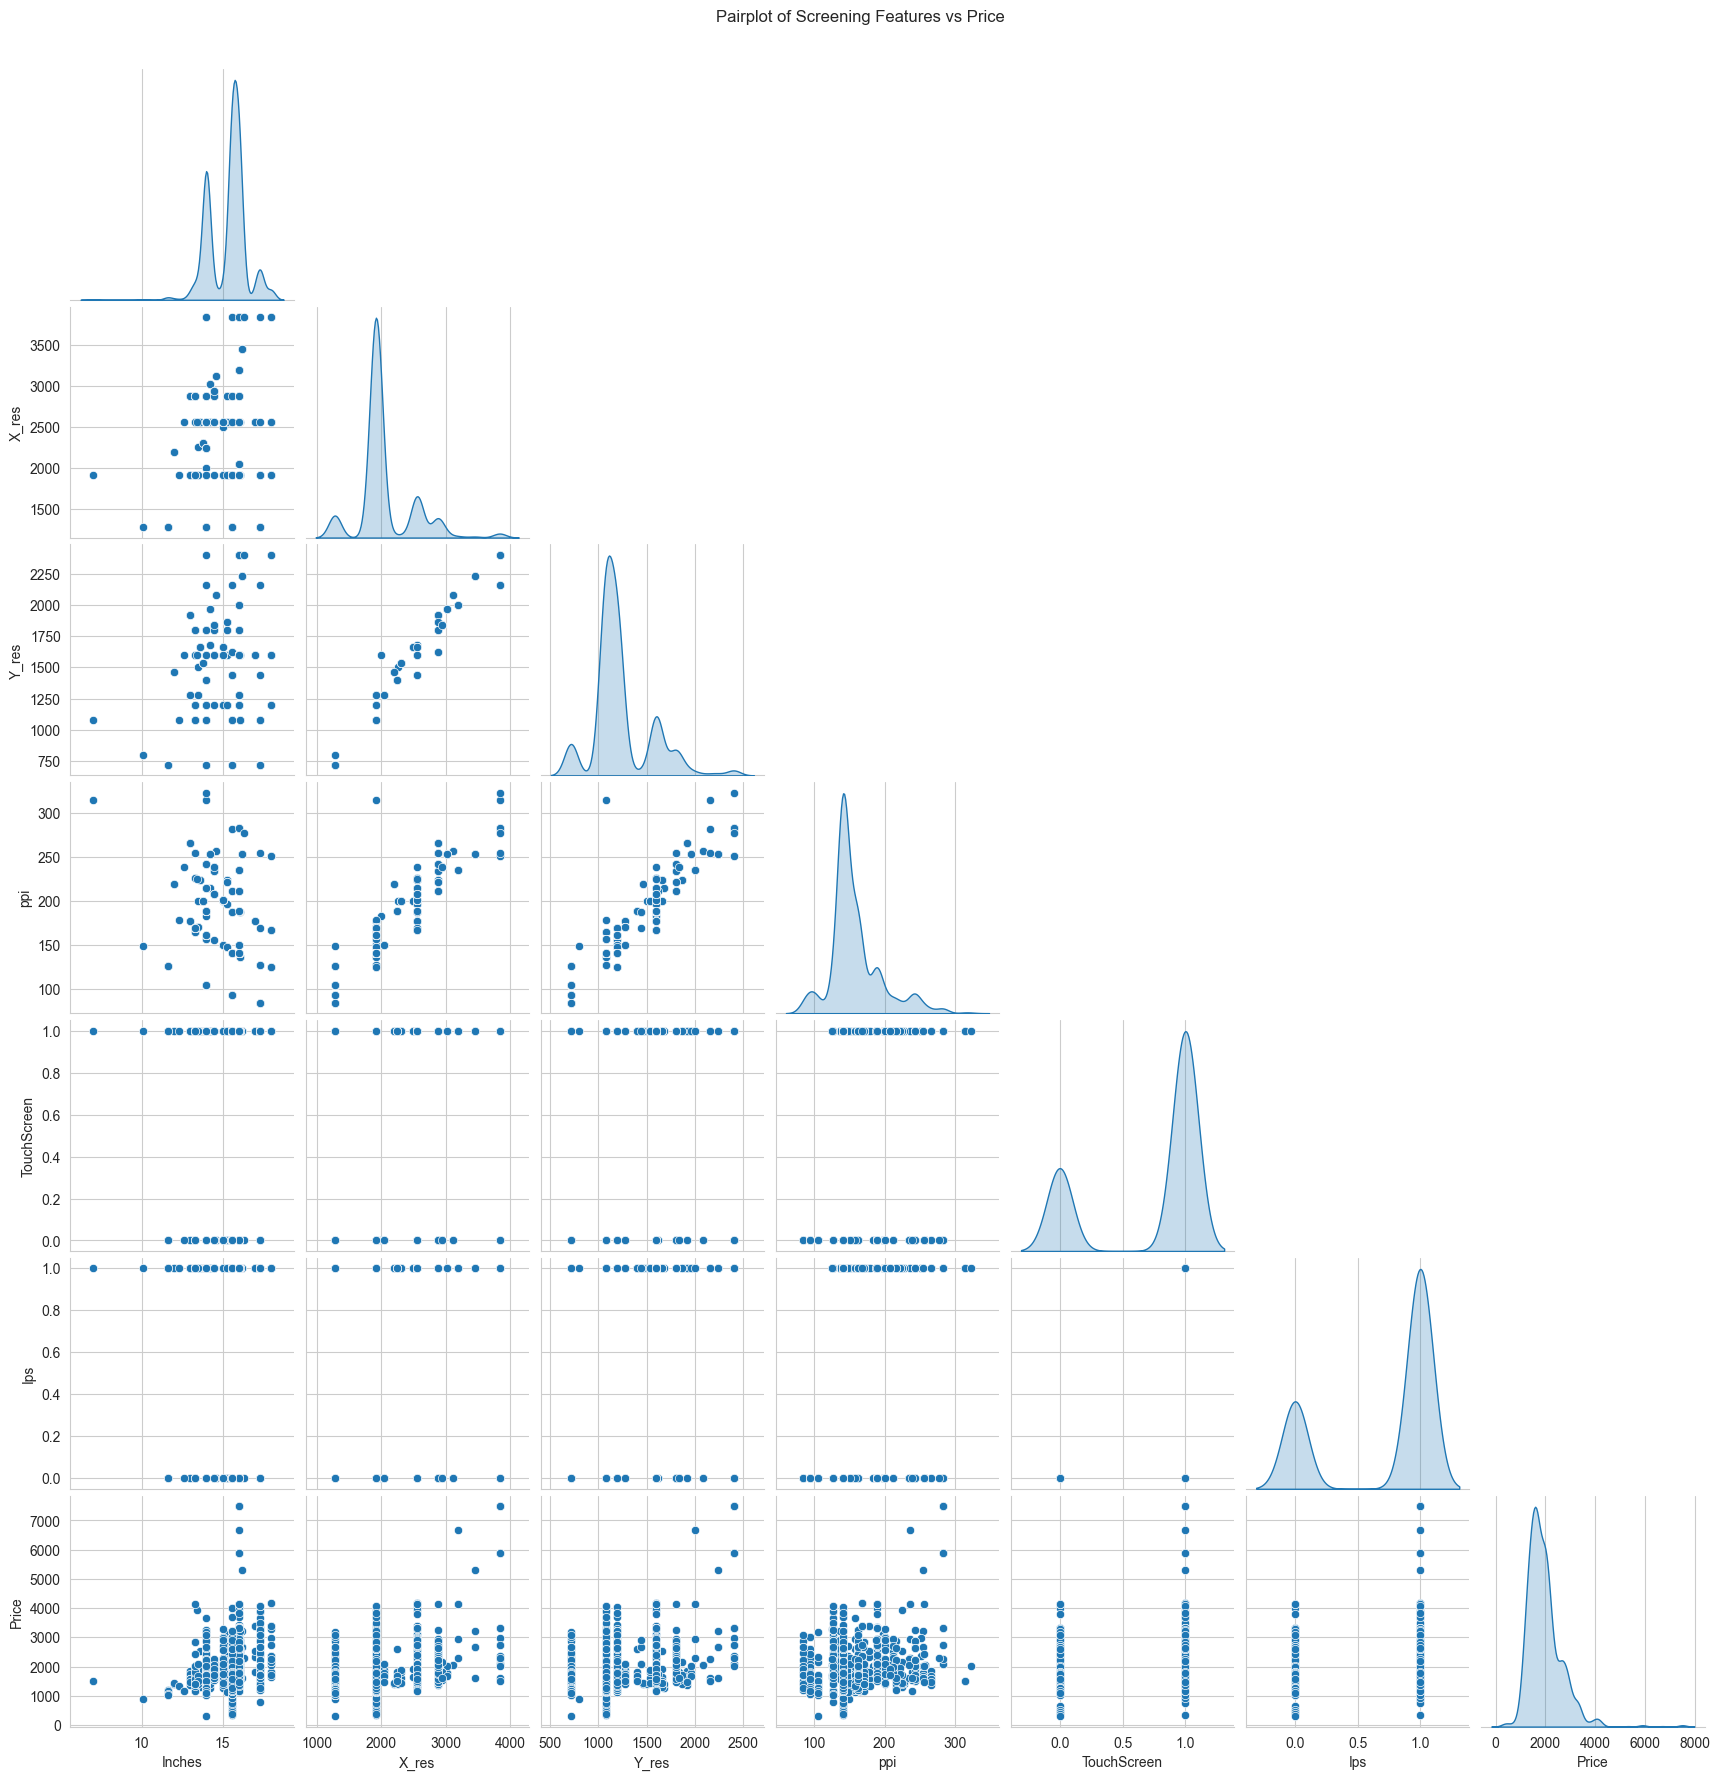

In [16]:
sns.pairplot(df[screening_cols + [target_col]], diag_kind='kde', corner=True)
plt.suptitle('Pairplot of Screening Features vs Price', y=1.02)

Text(0.5, 1.02, 'Pairplot of General Features vs Price')

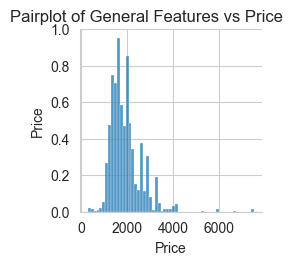

In [17]:
sns.pairplot(df[general_cols + [target_col]])# diag_kind='kde', corner=True)
plt.suptitle('Pairplot of General Features vs Price', y=1.02)

In [18]:

"""
from sklearn.cluster import KMeans
def correlation_analysis(df):
   for i in screening_cols: 
    x_train = df[i,target_col]
    kmeans = KMeans(n_clusters=7).fit(x_train)
    px.scatter(x=x_train[i],y=x_train[target_col],color = kmeans.labesls)


correlation_analysis(df)
"""
    

'\nfrom sklearn.cluster import KMeans\ndef correlation_analysis(df):\n   for i in screening_cols: \n    x_train = df[i,target_col]\n    kmeans = KMeans(n_clusters=7).fit(x_train)\n    px.scatter(x=x_train[i],y=x_train[target_col],color = kmeans.labesls)\n\n\ncorrelation_analysis(df)\n'

In [19]:
"""
import plotly.express as px
from sklearn.cluster import KMeans

def correlation_analysis(df, screening_cols, target_col):
    for i in screening_cols:
        # 1. Correctly select the two columns for clustering
        x_train = df[[i, target_col]].dropna() # .dropna() ensures missing values don't break KMeans
        
        # 2. Fit the KMeans model
        kmeans = KMeans(n_clusters=7, random_state=42).fit(x_train)
        
        # 3. Create the scatter plot using the correct labels attribute
        fig = px.scatter(
            x=x_train[i], 
            y=x_train[target_col], 
            color=kmeans.labels_.astype(str), # Converted to str so Plotly treats clusters as distinct colors
            labels={'x': i, 'y': target_col},
            title=f"K-Means Clustering: {i} vs {target_col}"
        )
        
        # 4. Explicitly show the plot in the loop
        fig.show()

# Example usage (Make sure your lists match your actual dataframe columns):
# correlation_analysis(df, screening_cols=['col1', 'col2'], target_col='target')


correlation_analysis(df, screening_cols=performance_cols, target_col=target_col)

"""

'\nimport plotly.express as px\nfrom sklearn.cluster import KMeans\n\ndef correlation_analysis(df, screening_cols, target_col):\n    for i in screening_cols:\n        # 1. Correctly select the two columns for clustering\n        x_train = df[[i, target_col]].dropna() # .dropna() ensures missing values don\'t break KMeans\n\n        # 2. Fit the KMeans model\n        kmeans = KMeans(n_clusters=7, random_state=42).fit(x_train)\n\n        # 3. Create the scatter plot using the correct labels attribute\n        fig = px.scatter(\n            x=x_train[i], \n            y=x_train[target_col], \n            color=kmeans.labels_.astype(str), # Converted to str so Plotly treats clusters as distinct colors\n            labels={\'x\': i, \'y\': target_col},\n            title=f"K-Means Clustering: {i} vs {target_col}"\n        )\n\n        # 4. Explicitly show the plot in the loop\n        fig.show()\n\n# Example usage (Make sure your lists match your actual dataframe columns):\n# correlation_an

### Preparing data

In [20]:
df = pd.read_csv('C:\\Users\\zakaria\\Documents\\ML\\laptop_price_predictor_project\\backend\\data\\processed\\laptop_scrap_data_cleaned.csv')    

In [ ]:

import pandas as pd
import numpy as np
from sklearn import pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
import re




def extract_features(df):

    df['Gpu_brand'] = df['Gpu'].apply(lambda x: 'NVIDIA' if 'NVIDIA' in str(x) else 
                                          ('Intel' if 'Intel' in str(x) else 
                                           ('AMD' if 'AMD' in str(x) else 
                                            ('Qualcomm' if 'Qualcomm' in str(x) else 'Other'))))
    
    df['Cpu_Brand'] = df['Cpu'].str.split().str[0]
    df['Storage_performance'] = df['Storage_Category'].apply(lambda x: 'standard' if 'standard' in str(x) else 
                                              ('High' if 'High' in str(x) else ("Very High" if "Very High" in str(x) else("Basic" if "Basic" in str(x) else "Minimal" if "Minimal" in str(x) else 'Other'))))
    
    pattern = r'(Intel Core i\d|Intel Core Ultra \d|AMD Ryzen AI \d|AMD Ryzen \d|AMD Athlon \w+|Intel Celeron|Intel Pentium)'
    df['Cpu_Brand'] = df['Cpu'].str.extract(pattern, flags=re.IGNORECASE)
    df['Cpu_Brand'] = df['Cpu_Brand'].fillna('Other')

    #feature engennering for the typename column 
    #describtion of lap Prestige  for MSi |XPS for DELL |ThinkPad for Lenovo MEANS THE LAP IS WITH HIGHT PERFORMANCE 
    #WE CAN SAY THE ARE PREMKIUM LAPTOPS "1 if premium else 0" 
    premium_keywords = 'Prestige|Pro|EliteBook|ThinkPad|XPS|Spectre'
    df['Is_Premium_Tier'] = df['TypeName'].str.contains(premium_keywords, case=False, regex=True).astype(int) 
    #next generation laptops ckeck for lap with integrated IA 
    df['Is_AI_Ready'] = df['TypeName'].str.contains(r'AI\+', case=False, regex=True).astype(int)
    # Clean the original text to keep just the main Series Name ( "MSI Prestige")
    # This grabs the first two words of the string
    df['Laptop_Series'] = df['TypeName'].str.split().str[:2].str.join(' ')
    return df

def drop_columns(df):
    df = df.drop(["TypeName","Cpu","Storage_Category"], axis=1)
    return df


def spliting_data(df):
    y = df.pop("Price")
    x = df
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=45)
    return x_train, x_test, y_train, y_test

def getting_categorical(df):
    all_cols = x_train.columns.tolist()
    categorical = [col for col in ["Cpu_Brand", 'Storage_performance', "Storage_Type", "OpSys", "Company", "Laptop_Series"] if col in all_cols]
    return categorical

def encoding_col(x_train, x_test):
    # Filter categorical columns that actually exist in the data

    
    # Identify numeric columns by checking data type
    numeric = [col for col in all_cols if col not in categorical and x_train[col].dtype in ['int64', 'int32', 'float64', 'float32']]
    
    # Build transformers list
    transformers = [
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)
    ]
    
    # Only add numeric transformer if there are numeric columns
    if numeric:
        transformers.append(('num', 'passthrough', numeric))
    
    preprocessor = ColumnTransformer(transformers=transformers)
    
    x_train_encoded = preprocessor.fit_transform(x_train)
    x_test_encoded = preprocessor.transform(x_test)
    
    # Convert sparse to dense if needed
    if hasattr(x_train_encoded, 'toarray'):
        x_train_encoded = x_train_encoded.toarray()
    if hasattr(x_test_encoded, 'toarray'):
        x_test_encoded = x_test_encoded.toarray()
    
    # Get feature names after encoding
    try:
        feature_names = preprocessor.get_feature_names_out()
    except AttributeError:
        # For older sklearn versions, construct feature names manually
        feature_names = None
    
    if feature_names is not None:
        x_train_final = pd.DataFrame(x_train_encoded, columns=feature_names, index=x_train.index)
        x_test_final = pd.DataFrame(x_test_encoded, columns=feature_names, index=x_test.index)
    else:
        x_train_final = pd.DataFrame(x_train_encoded, index=x_train.index)
        x_test_final = pd.DataFrame(x_test_encoded, index=x_test.index)

    return x_train_final, x_test_final,categorical


  


    




In [22]:



import pandas as pd







df = pd.read_csv('C:\\Users\\zakaria\\Documents\\ML\\laptop_price_predictor_project\\backend\\data\\processed\\laptop_scrap_data_cleaned.csv')     
df = extract_features(df)
df =drop_columns(df)
df.to_csv('C:\\Users\\zakaria\\Documents\\ML\\laptop_price_predictor_project\\backend\\data\\processed\\laptop_scrap_data_ready.csv')     
x_train, x_test, y_train, y_test = spliting_data(df)
x_train_enc,x_test_enc,categorical = encoding_col(x_train, x_test)









In [ ]:
from catboost import CatBoostRegressor

model = CatBoostRegressor(iterations=1000, learning_rate=0.1, depth=6)
model.fit(x_train_enc, y_train)

In [24]:
y_predict = model.predict(x_test_enc)

from sklearn.metrics import mean_squared_error,root_mean_squared_error,mean_absolute_error,r2_score
mse=mean_squared_error(y_predict,y_test)
rmse = root_mean_squared_error(y_predict,y_test)
mae = mean_absolute_error(y_predict,y_test)
acc =r2_score(y_predict,y_test)

print("the mse",mse)
print("the mae",mae)
print("the rmse",rmse)
print("r2_score",acc)

the mse 2254.976203618083
the mae 12.251738591666872
the rmse 47.486589724027176
r2_score 0.9938902004693803


In [25]:
#testing the model on reel data

x_test.columns

Index(['Company', 'Inches', 'ScreenResolution', 'Gpu', 'OpSys', 'TouchScreen',
       'Ips', 'X_res', 'Y_res', 'ppi', 'Dedicated_Gpu', 'Ram_GB', 'Weight_kg',
       'SSD', 'HHD', 'Storage_Type', 'Total_Storage_GB', 'X_res__winsor',
       'Y_res__winsor', 'ppi__winsor', 'Ram_GB__winsor', 'Weight_kg__winsor',
       'SSD__winsor', 'HHD__winsor', 'Total_Storage_GB__winsor',
       'Price__winsor', 'Gpu_brand', 'Cpu_Brand', 'Storage_performance',
       'Is_Premium_Tier', 'Is_AI_Ready', 'Laptop_Series'],
      dtype='str')

### SAVING THE DATA INTO THE DISK


In [29]:
import joblib
pipline_to_save ={
    "model":model,
    "encoding_col":encoding_col,
    "spliting_data":spliting_data,
    "extract_features":extract_features,
    "drop_columns":drop_columns
}

file_name = "laptop_price_model.joblib"
joblib.dump(pipline_to_save,file_name)

print("the model saved to the disk")

the model saved to the disk


### LOAD THE MODEL FROM THE DISK

In [30]:
file_name = "laptop_price_model.joblib"
load_pipline = joblib.load(file_name )